# Experiment 10: L2, Dropout and Early Stopping Comparison

A medical-records team sees a large MLP memorise a small diabetes dataset. We generate 500 tabular records and compare a high-capacity baseline with L2 penalties, dropout and early stopping.

**Tools:** TensorFlow, Keras, NumPy, Matplotlib.

**Embedded graph preview:** Static preview image included to match the reference notebooks. Run the code cell to produce plots from this experiment’s Python data.

## Tasks

1. Train a deliberately large baseline and plot overfitting.  2. Compare three L2 strengths.  3. Compare dropout rates 0.2, 0.3 and 0.5.  4. Train with early stopping on validation loss.  5. Tabulate test accuracy and train–test gap.

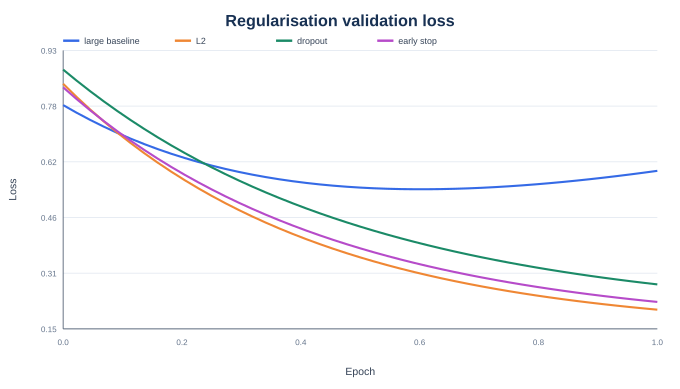

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

tf.keras.utils.set_random_seed(10)
rng = np.random.default_rng(10)
X = rng.normal(size=(500, 8)).astype("float32")
logit = 1.2*X[:,0] - .9*X[:,1] + .6*X[:,2] + .35*X[:,3]*X[:,4]
y = (rng.random(500) < 1/(1+np.exp(-logit))).astype("float32")
Xtr, Xte, ytr, yte = train_test_split(X,y,test_size=.25,random_state=10,stratify=y)
scaler = StandardScaler(); Xtr=scaler.fit_transform(Xtr).astype("float32"); Xte=scaler.transform(Xte).astype("float32")

def build_model(reg=0., drop=0.):
    layers=[tf.keras.layers.Input((8,)), tf.keras.layers.Dense(256,activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(reg))]
    if drop: layers.append(tf.keras.layers.Dropout(drop))
    layers += [tf.keras.layers.Dense(128,activation="relu",
              kernel_regularizer=tf.keras.regularizers.l2(reg))]
    if drop: layers.append(tf.keras.layers.Dropout(drop))
    layers += [tf.keras.layers.Dense(64,activation="relu"),tf.keras.layers.Dense(1,activation="sigmoid")]
    m=tf.keras.Sequential(layers); m.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"]); return m

rows=[]; curves={}
settings=[("baseline",0.,0.,False)]
settings += [(f"L2 {v:g}",v,0.,False) for v in [.0001,.001,.01]]
settings += [(f"dropout {v}",0.,v,False) for v in [.2,.3,.5]]
settings += [("early stopping",0.,0.,True)]
for name, reg, drop, early in settings:
    m=build_model(reg,drop)
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss",patience=5,restore_best_weights=True)] if early else []
    h=m.fit(Xtr,ytr,validation_split=.25,epochs=60,batch_size=24,verbose=0,callbacks=callbacks)
    tr_acc=m.evaluate(Xtr,ytr,verbose=0)[1]; te_prob=m.predict(Xte,verbose=0).ravel()
    te_acc=accuracy_score(yte,(te_prob>=.5).astype(int))
    rows.append({"model":name,"epochs":len(h.history["loss"]),"train accuracy":tr_acc,
                 "test accuracy":te_acc,"train-test gap":tr_acc-te_acc})
    curves[name]=(h.history["loss"],h.history["val_loss"])
print(pd.DataFrame(rows).round(3).to_string(index=False))
plt.figure(figsize=(9,5))
for name in ["baseline","L2 0.001","dropout 0.3","early stopping"]:
    tr,va=curves[name]; plt.plot(va,label=name)
plt.xlabel("Epoch"); plt.ylabel("Validation loss"); plt.title("Validation curves for representative regularisers")
plt.grid(alpha=.2); plt.legend(); plt.tight_layout(); plt.show()